In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## STEP 1 — Load & Inspect

In [2]:
# Load the dataset
df= pd.read_csv(r"C:\Users\DELL\Downloads\fashion_dataset_150k.csv")
df

,Customer_ID,Age,Gender,Location,Product_ID,Category,Brand,Color,Size,Season,...,Discount,Rating,Purchase_Date,Quantity,Sales_Amount,Trend_Score,Social_Media_Influence,Return_Status,Recommendation_Clicked,Customer_Feedback
0,C_14165,31,Female,Mumbai,P_22280,Salwar Suit,Pantaloons,Blush,XL,Summer,...,10,1.9,2023-04-03,1,2745.0,45.0,66.4,Kept,No,Negative
1,C_65392,24,Female,Surat,P_46421,Lehenga,Raymond,Lavender,M,Summer,...,30,2.3,2023-03-28,1,3682.0,93.4,75.3,Kept,No,Positive
2,C_59615,18,Female,Bengaluru,P_82357,Jeans,Aurelia,Turquoise,XXL,Winter,...,25,3.5,2023-12-06,2,1800.0,54.5,49.5,Kept,No,Positive
3,C_23238,25,Female,Kanpur,P_46434,Lehenga,Anouk,Mustard,M,Summer,...,10,2.2,2022-05-23,1,7128.0,69.4,21.7,Kept,Yes,Positive
4,C_93886,33,Male,Varanasi,P_83000,Shirt,Van Heusen,Peach,M,Summer,...,15,2.1,2022-05-27,2,2482.0,79.7,29.5,Kept,Yes,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,C_19820,19,Female,Vadodara,P_63069,Saree,H&M,Turquoise,M,Monsoon,...,30,2.3,2024-07-13,1,2800.0,65.2,83.2,Kept,No,Negative
149996,C_88086,32,Female,Indore,P_38401,Lehenga,Ritu Kumar,Maroon,L,Festive,...,40,2.8,2023-11-14,3,6192.0,52.7,91.5,Kept,Yes,Negative
149997,C_54506,30,Female,Rajkot,P_20658,Kurti,Suti,Rust,S,Festive,...,5,2.7,2022-09-17,2,2812.0,37.9,100.0,Kept,Yes,Negative
149998,C_59765,59,Female,Lucknow,P_87176,Kurti,Biba,Mustard,M,Festive,...,0,1.9,2023-09-10,1,1160.0,86.8,16.3,Returned,No,Negative


In [3]:
# Shape
print(df.shape)

# First 5 rows
print(df.head())

# Column names and data types
print(df.dtypes)

# Missing values per column
print(df.isnull().sum())

# Duplicate rows
print(df.duplicated().sum())

# Summary statistics for numeric columns
print(df.describe())

(150000, 21)
  Customer_ID  Age  Gender   Location Product_ID     Category       Brand  \
0     C_14165   31  Female     Mumbai    P_22280  Salwar Suit  Pantaloons   
1     C_65392   24  Female      Surat    P_46421      Lehenga     Raymond   
2     C_59615   18  Female  Bengaluru    P_82357        Jeans     Aurelia   
3     C_23238   25  Female     Kanpur    P_46434      Lehenga       Anouk   
4     C_93886   33    Male   Varanasi    P_83000        Shirt  Van Heusen   

       Color Size  Season  ...  Discount  Rating  Purchase_Date Quantity  \
0      Blush   XL  Summer  ...        10     1.9     2023-04-03        1   
1   Lavender    M  Summer  ...        30     2.3     2023-03-28        1   
2  Turquoise  XXL  Winter  ...        25     3.5     2023-12-06        2   
3    Mustard    M  Summer  ...        10     2.2     2022-05-23        1   
4      Peach    M  Summer  ...        15     2.1     2022-05-27        2   

   Sales_Amount  Trend_Score  Social_Media_Influence  Return_Status

In [4]:
# Unique value count for each categorical column
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].nunique()} unique values")

# Value counts for key columns
print(df["Gender"].value_counts())
print(df["Category"].value_counts())
print(df["Season"].value_counts())
print(df["Return_Status"].value_counts())
print(df["Size"].unique())

Customer_ID: 73242 unique values
Gender: 2 unique values
Location: 28 unique values
Product_ID: 72915 unique values
Category: 12 unique values
Brand: 35 unique values
Color: 28 unique values
Size: 6 unique values
Season: 4 unique values
Purchase_Date: 1186 unique values
Return_Status: 2 unique values
Recommendation_Clicked: 2 unique values
Customer_Feedback: 2 unique values
Gender
Female    93718
Male      56282
Name: count, dtype: int64
Category
Trousers       12654
Lehenga        12587
Saree          12572
Jacket         12562
Salwar Suit    12561
Shirt          12544
Dress          12533
Ethnic Wear    12487
Shorts         12417
Kurti          12407
Jeans          12351
T-Shirt        12325
Name: count, dtype: int64
Season
Winter     41716
Summer     39246
Monsoon    34807
Festive    34231
Name: count, dtype: int64
Return_Status
Kept        124437
Returned     25563
Name: count, dtype: int64
<ArrowStringArray>
['XL', 'M', 'XXL', 'S', 'L', 'XS']
Length: 6, dtype: str


## STEP 2 — Data Cleaning

In [5]:
# Parse Purchase_Date from string to datetime
df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"])

# Check date range
print(df["Purchase_Date"].min(), df["Purchase_Date"].max())

# Strip whitespace and title-case all text columns
text_cols = ["Gender","Category","Brand","Color","Size","Season",
             "Return_Status","Recommendation_Clicked","Customer_Feedback"]
for col in text_cols:
    df[col] = df[col].str.strip().str.title()

# Make Size an ordered categorical
SIZE_ORDER = ["XS","S","M","L","XL","XXL"]
df["Size"] = pd.Categorical(df["Size"], categories=SIZE_ORDER, ordered=True)

# Clip Discount and Rating to valid ranges
df["Discount"] = df["Discount"].clip(0, 100)
df["Rating"]   = df["Rating"].clip(1, 5)

# Verify Sales_Amount matches the formula Price × Qty × (1 - Discount/100)
df["Calc_Sales"] = (df["Price"] * df["Quantity"] * (1 - df["Discount"] / 100)).round(2)
mismatch = (df["Calc_Sales"] - df["Sales_Amount"]).abs() > 1
print(f"Mismatched rows: {mismatch.sum()}")
df.drop(columns=["Calc_Sales"], inplace=True)

2022-01-01 00:00:00 2025-03-31 00:00:00
Mismatched rows: 0


## STEP 3 — Feature Engineering

In [6]:
# Time-based features
df["Year"]       = df["Purchase_Date"].dt.year
df["Month"]      = df["Purchase_Date"].dt.month
df["Month_Name"] = df["Purchase_Date"].dt.strftime("%b")
df["Quarter"]    = df["Purchase_Date"].dt.to_period("Q").astype(str)
df["DayOfWeek"]  = df["Purchase_Date"].dt.day_name()
df["IsWeekend"]  = df["Purchase_Date"].dt.dayofweek >= 5

# Financial features
df["Effective_Price"]  = (df["Price"] * (1 - df["Discount"] / 100)).round(2)
df["Revenue_per_Unit"] = (df["Sales_Amount"] / df["Quantity"]).round(2)

# Discount bands
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-1, 0, 10, 20, 30, 60],
    labels=["No Discount", "1-10%", "11-20%", "21-30%", "31%+"]
)

# Age groups
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[15, 24, 34, 44, 54, 72],
    labels=["16-24", "25-34", "35-44", "45-54", "55+"]
)

# Price tier (quartile-based)
df["Price_Tier"] = pd.qcut(
    df["Price"], q=4,
    labels=["Budget", "Mid-Range", "Premium", "Luxury"]
)

# Binary target flags (0 or 1)
df["Returned"]    = (df["Return_Status"]== "Returned").astype(int)
df["Rec_Clicked"] = (df["Recommendation_Clicked"] == "Yes").astype(int)
df["Positive_FB"] = (df["Customer_Feedback"]       == "Positive").astype(int)

# High-trend flag (top 25% Trend_Score)
df["High_Trend"] = (df["Trend_Score"] >= df["Trend_Score"].quantile(0.75)).astype(int)

# Class imbalance check
print(df["Return_Status"].value_counts())
print(df["Return_Status"].value_counts(normalize=True) * 100)

Return_Status
Kept        124437
Returned     25563
Name: count, dtype: int64
Return_Status
Kept        82.958
Returned    17.042
Name: proportion, dtype: float64


## STEP 4A — Univariate Analysis

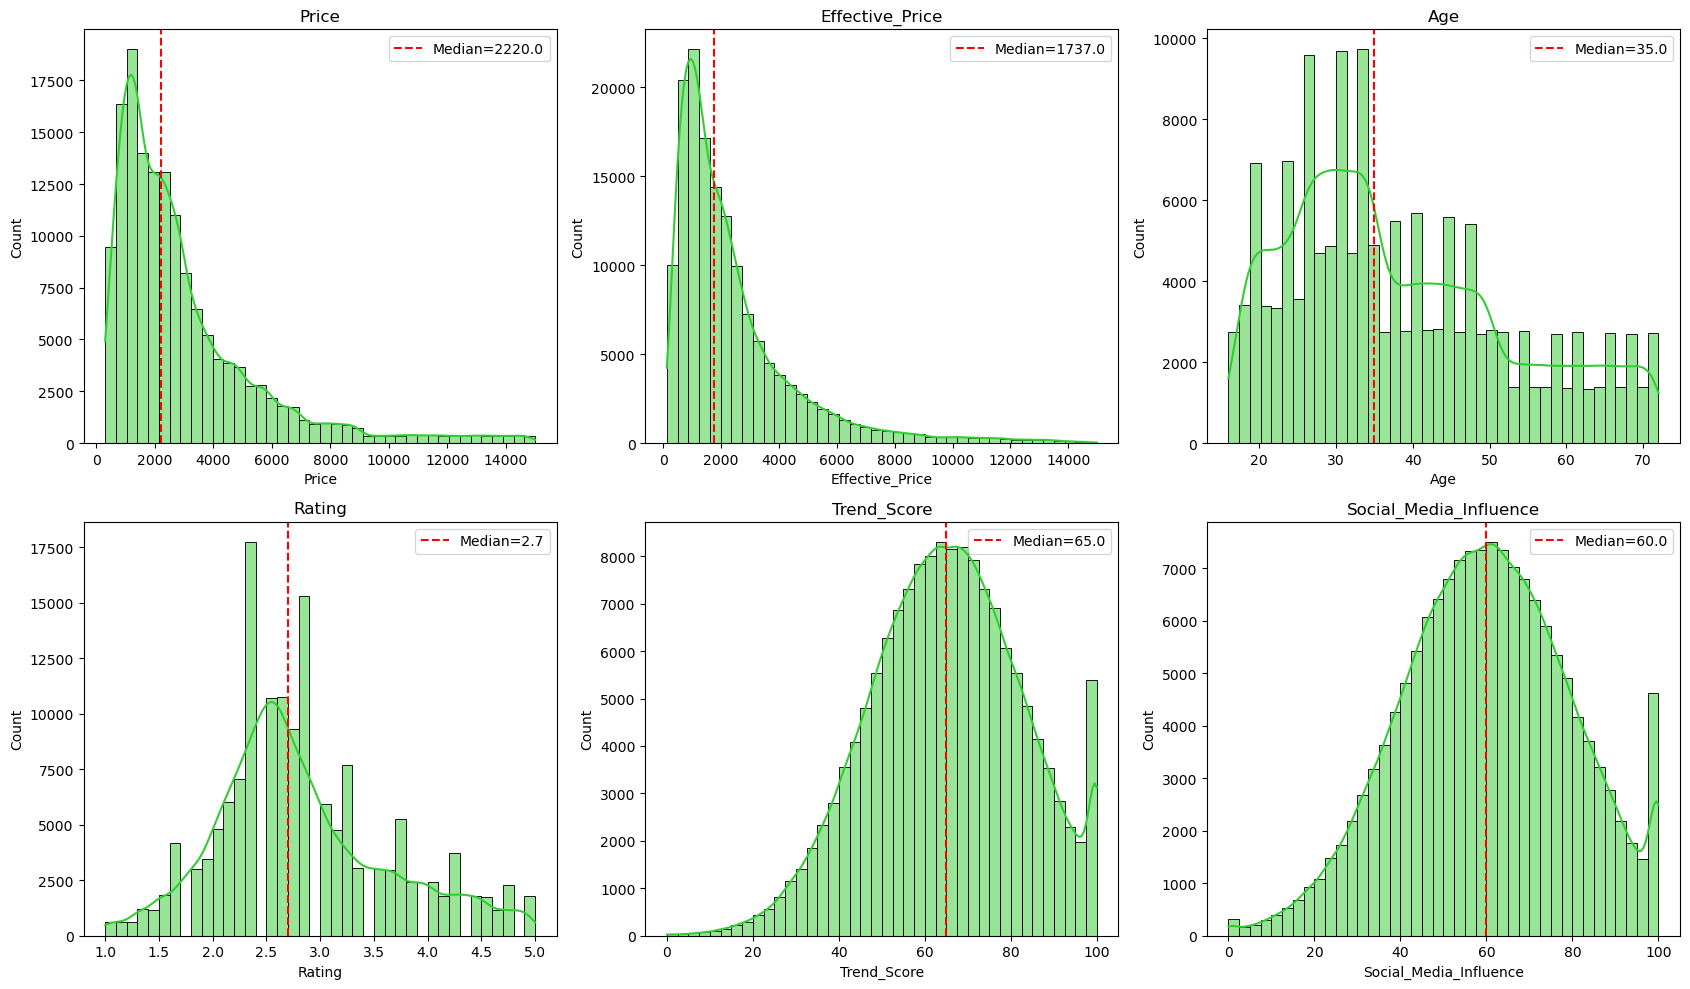

In [7]:
# --- Numeric distributions ---
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
num_cols = ["Price","Effective_Price","Age","Rating","Trend_Score","Social_Media_Influence"]
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], ax=ax, kde=True, bins=40,color="limegreen")
    ax.axvline(df[col].median(), color="red", ls="--", label=f"Median={df[col].median():.1f}")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

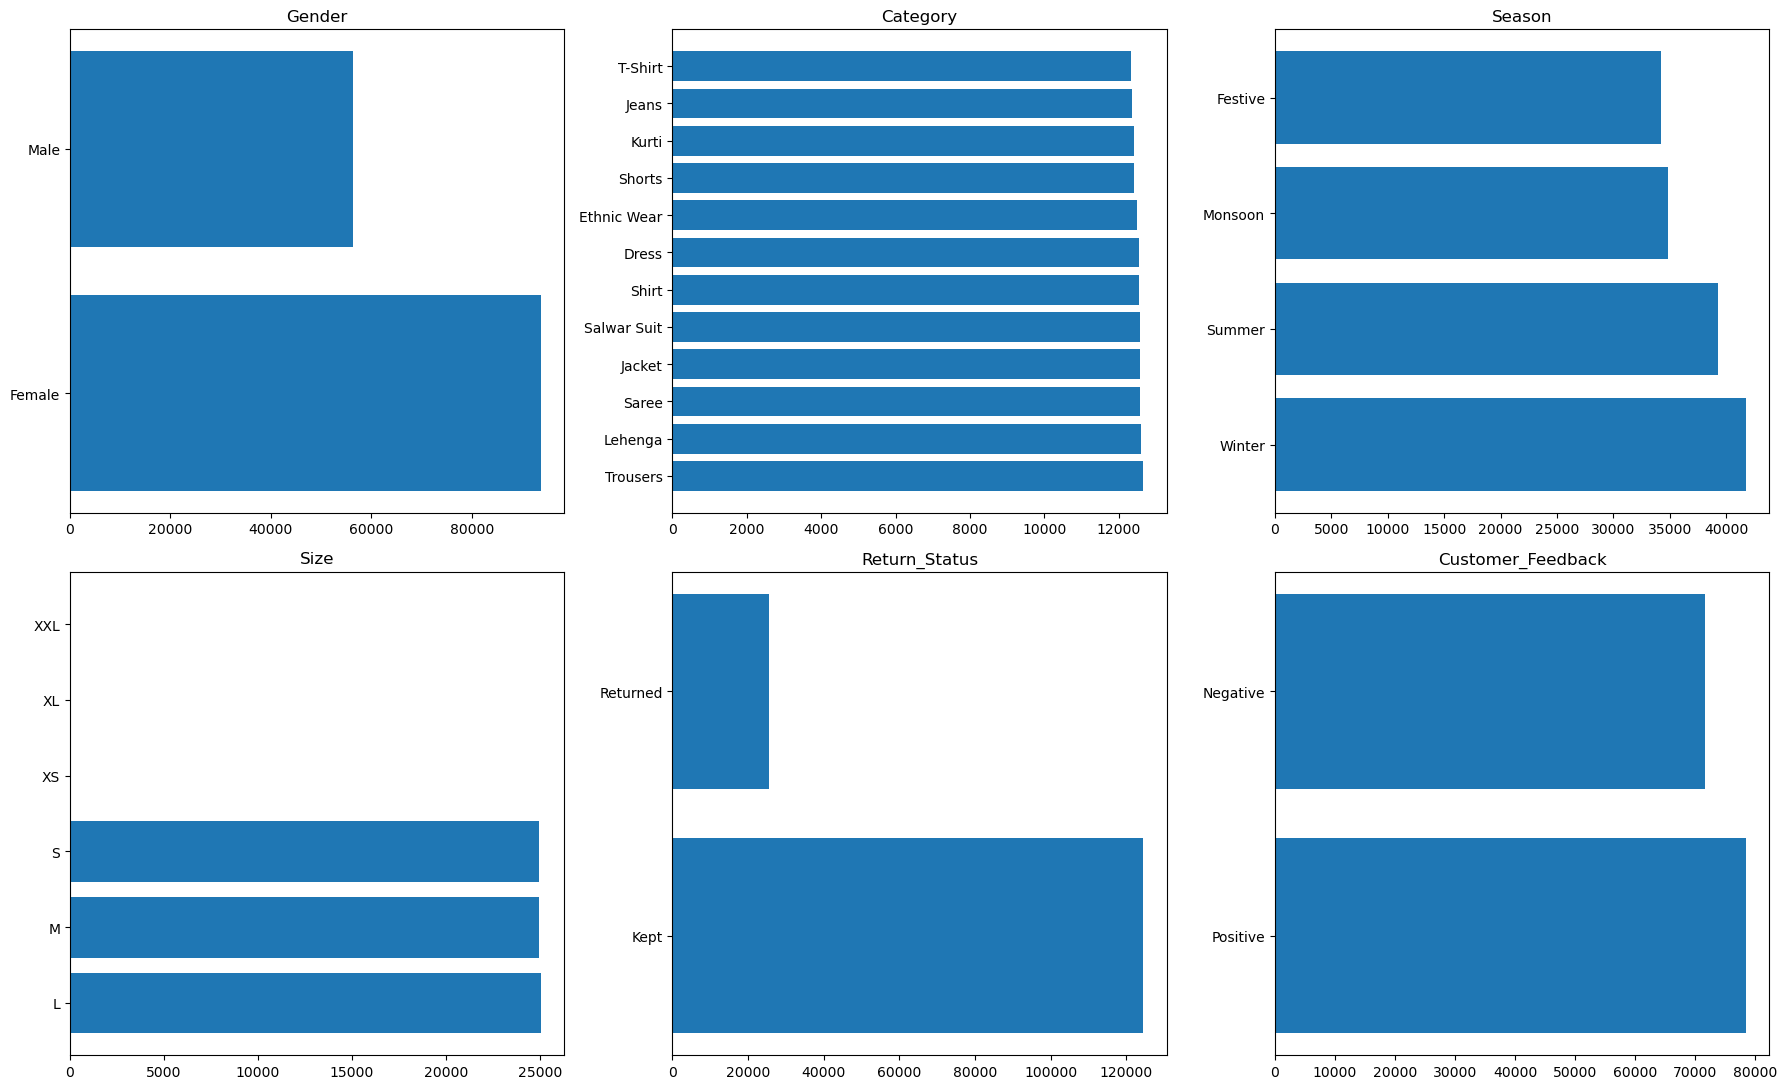

In [8]:
# --- Categorical frequency bar charts ---
cat_cols = ["Gender","Category","Season","Size","Return_Status","Customer_Feedback"]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, col in zip(axes.flat, cat_cols):
    order = df[col].value_counts().index
    counts = df[col].value_counts()[order]
    ax.barh(order, counts)
    ax.set_title(col)
plt.tight_layout()
plt.show()

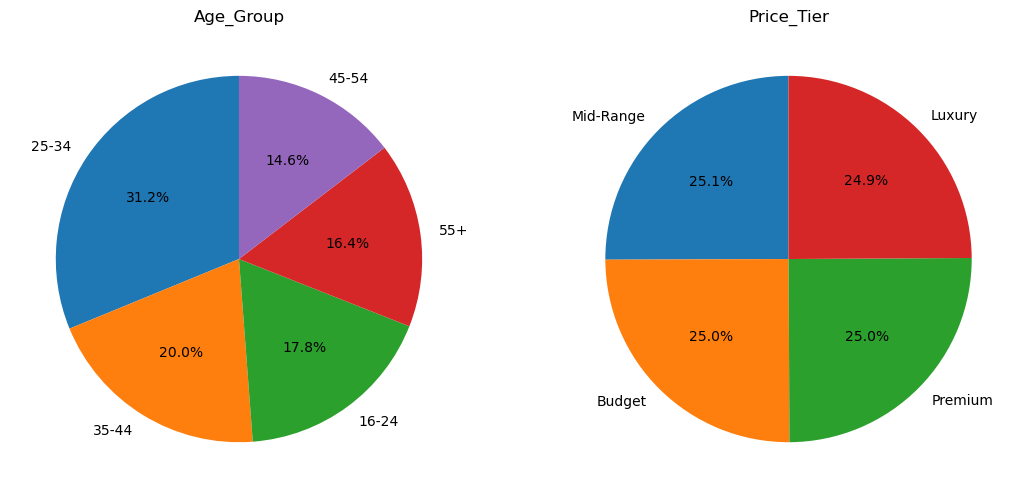

In [9]:
# --- Age Group & Price Tier pie charts ---
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, col in zip(axes, ["Age_Group", "Price_Tier"]):
    vc = df[col].value_counts()
    ax.pie(vc, labels=vc.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(col)
plt.show()

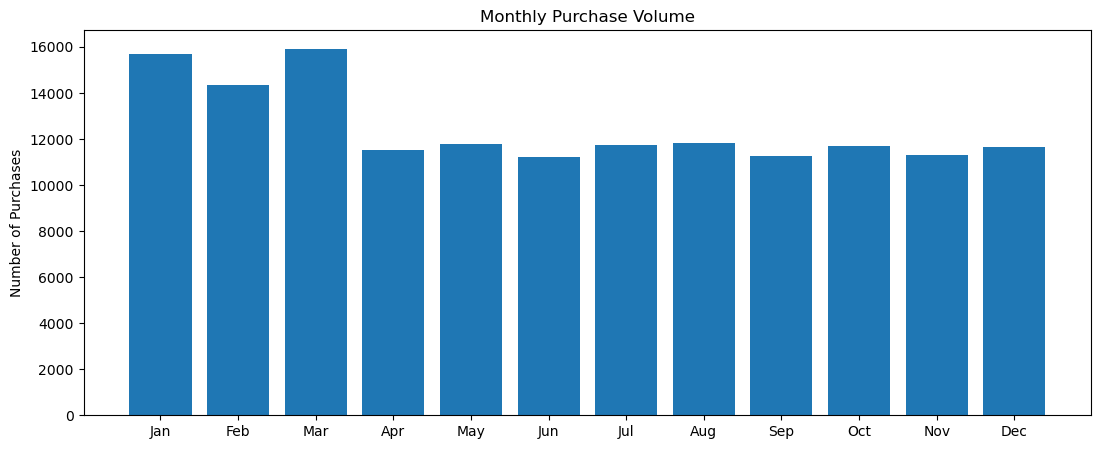

In [10]:
# --- Monthly purchase volume ---
MONTH_ORDER = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = df["Month_Name"].value_counts().reindex(MONTH_ORDER).fillna(0)
plt.figure(figsize=(13, 5))
plt.bar(monthly.index, monthly.values)
plt.title("Monthly Purchase Volume")
plt.ylabel("Number of Purchases")
plt.show()

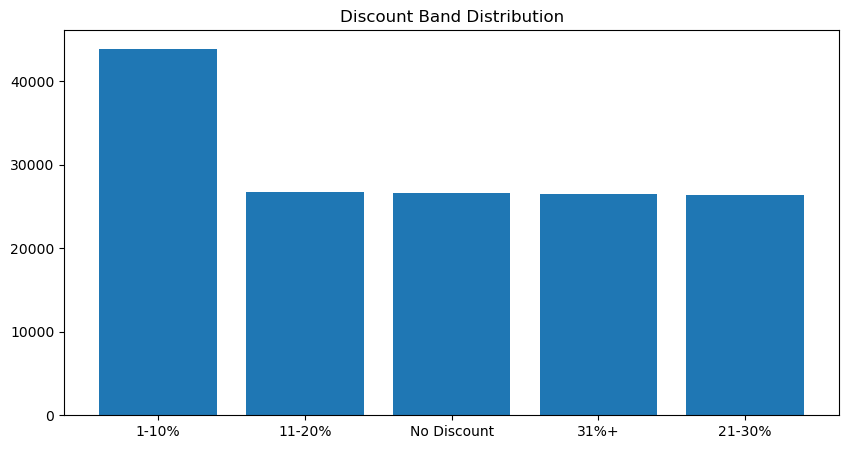

In [11]:
# --- Discount band distribution ---
vc = df["Discount_Band"].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(vc.index, vc.values)
plt.title("Discount Band Distribution")
plt.show()

## STEP 4B — Bivariate Analysis

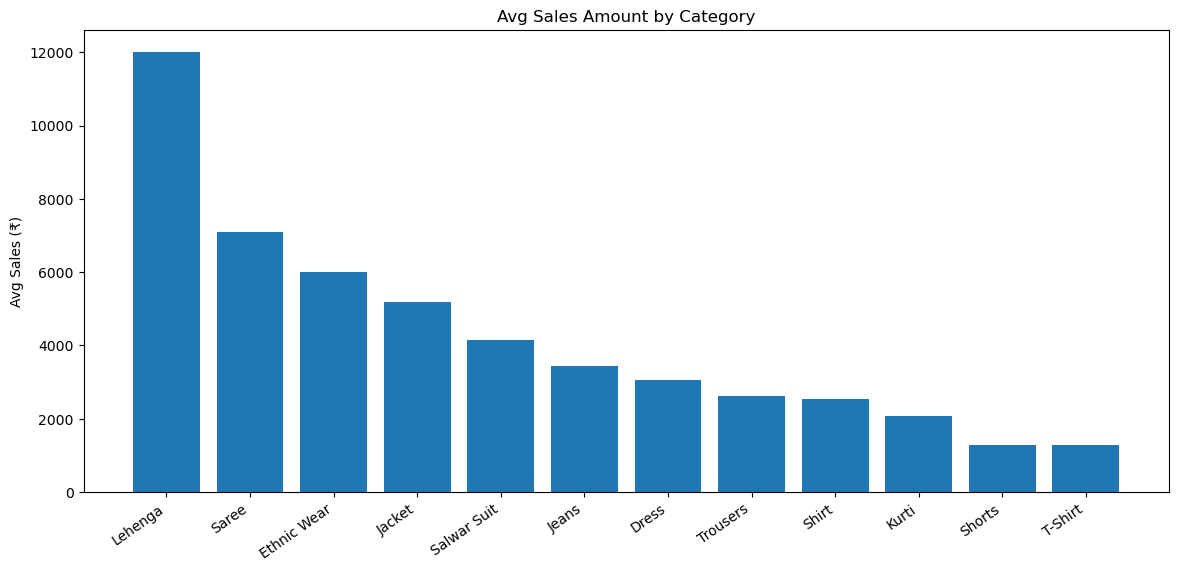

In [12]:
# --- Avg Sales Amount by Category ---
cat_sales = df.groupby("Category")["Sales_Amount"].mean().sort_values(ascending=False)
plt.figure(figsize=(14, 6))
plt.bar(cat_sales.index, cat_sales.values)
plt.xticks(rotation=35, ha="right")
plt.title("Avg Sales Amount by Category")
plt.ylabel("Avg Sales (₹)")
plt.show()

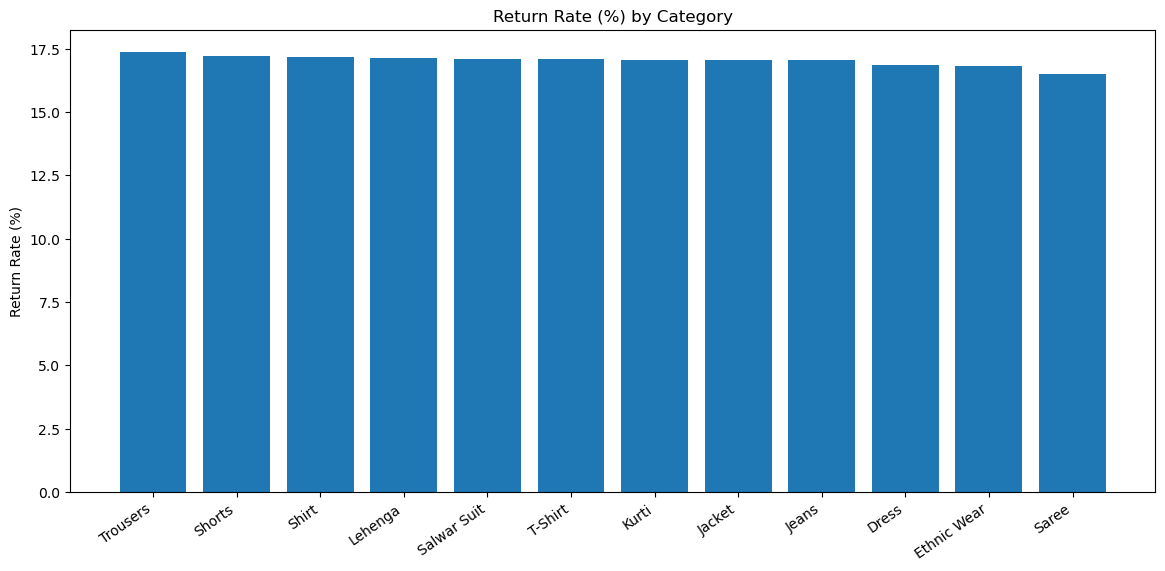

In [13]:
# --- Return Rate by Category ---
ret_cat = (df.groupby("Category")["Returned"].mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(14, 6))
plt.bar(ret_cat.index, ret_cat.values)
plt.xticks(rotation=35, ha="right")
plt.title("Return Rate (%) by Category")
plt.ylabel("Return Rate (%)")
plt.show()

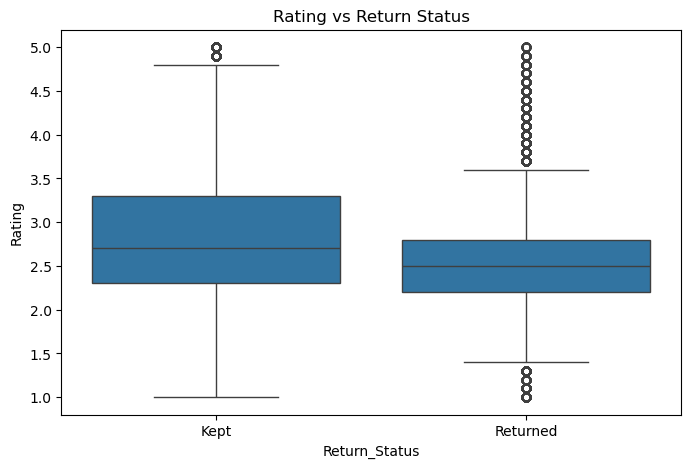

In [14]:
# --- Rating vs Return Status (box plot) ---
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Return_Status", y="Rating")
plt.title("Rating vs Return Status")
plt.show()

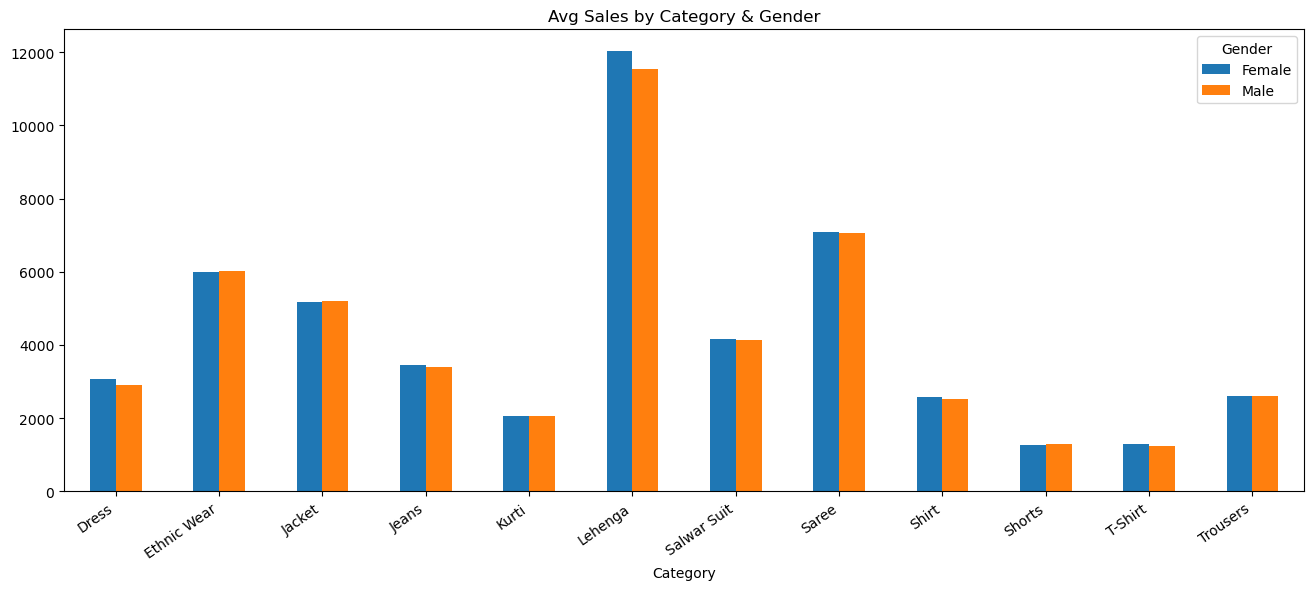

In [15]:
# --- Avg Sales by Category & Gender (grouped bar) ---
gc = df.groupby(["Category","Gender"])["Sales_Amount"].mean().unstack()
gc.plot(kind="bar", figsize=(16, 6))
plt.xticks(rotation=35, ha="right")
plt.title("Avg Sales by Category & Gender")
plt.show()

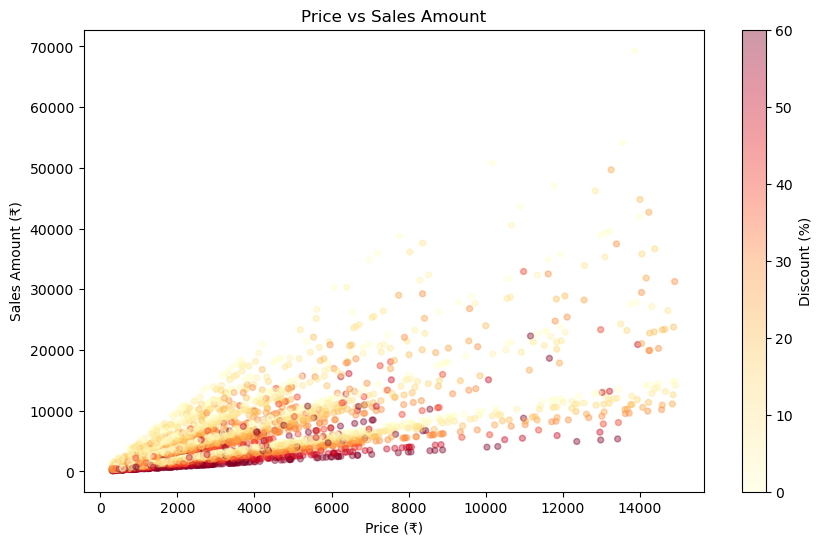

In [16]:
# --- Price vs Sales Amount scatter (coloured by Discount) ---
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(10, 6))
sc = plt.scatter(sample["Price"], sample["Sales_Amount"],
                 c=sample["Discount"], cmap="YlOrRd", alpha=0.4, s=18)
plt.colorbar(sc, label="Discount (%)")
plt.title("Price vs Sales Amount")
plt.xlabel("Price (₹)")
plt.ylabel("Sales Amount (₹)")
plt.show()

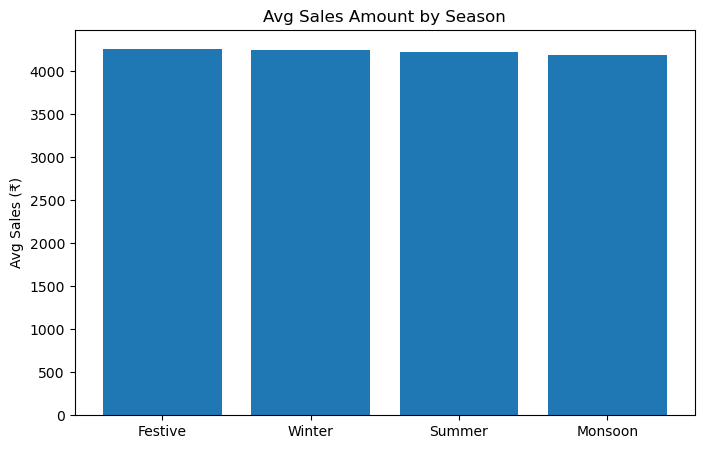

In [17]:
# --- Avg Sales by Season ---
season_sales = df.groupby("Season")["Sales_Amount"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(season_sales.index, season_sales.values)
plt.title("Avg Sales Amount by Season")
plt.ylabel("Avg Sales (₹)")
plt.show()

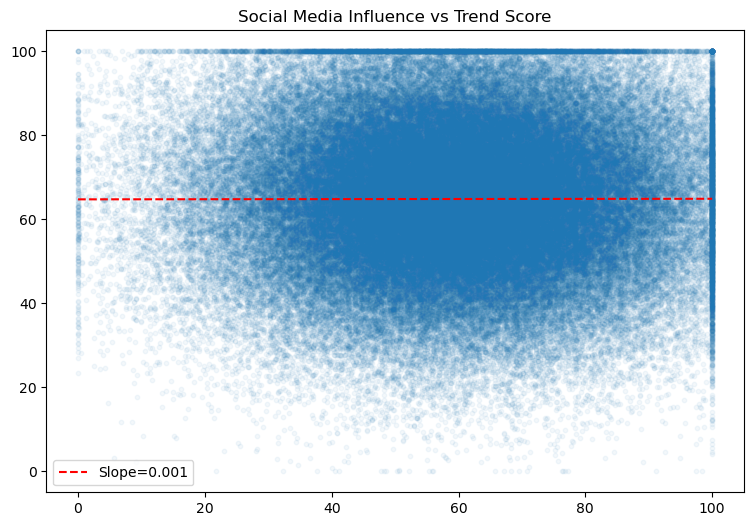

In [18]:
# --- Social Media Influence vs Trend Score ---
plt.figure(figsize=(9, 6))
plt.scatter(df["Social_Media_Influence"], df["Trend_Score"], alpha=0.05, s=10)
m, b = np.polyfit(df["Social_Media_Influence"], df["Trend_Score"], 1)
x_line = np.linspace(0, 100, 200)
plt.plot(x_line, m * x_line + b, "r--", label=f"Slope={m:.3f}")
plt.title("Social Media Influence vs Trend Score")
plt.legend()
plt.show()

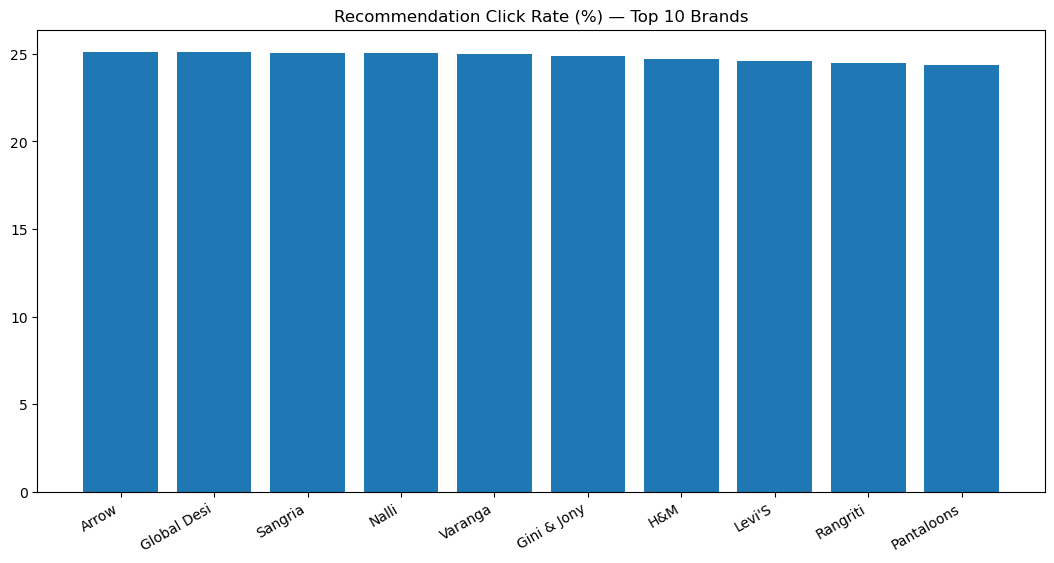

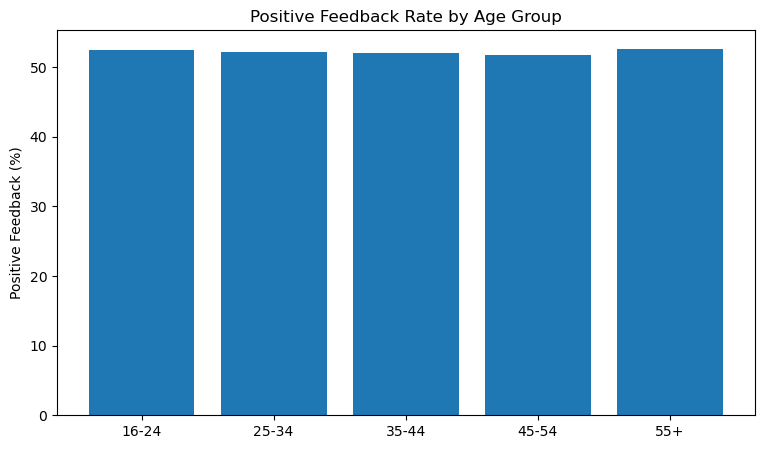

In [19]:
# --- Recommendation Click Rate by Brand (top 10) ---
brand_rec = (df.groupby("Brand")["Rec_Clicked"].mean() * 100).sort_values(ascending=False).head(10)
plt.figure(figsize=(13, 6))
plt.bar(brand_rec.index, brand_rec.values)
plt.xticks(rotation=30, ha="right")
plt.title("Recommendation Click Rate (%) — Top 10 Brands")
plt.show()

# --- Positive Feedback Rate by Age Group ---
age_fb = df.groupby("Age_Group", observed=True)["Positive_FB"].mean() * 100
plt.figure(figsize=(9, 5))
plt.bar(age_fb.index.astype(str), age_fb.values)
plt.title("Positive Feedback Rate by Age Group")
plt.ylabel("Positive Feedback (%)")
plt.show()

## STEP 4C — Multivariate Analysis

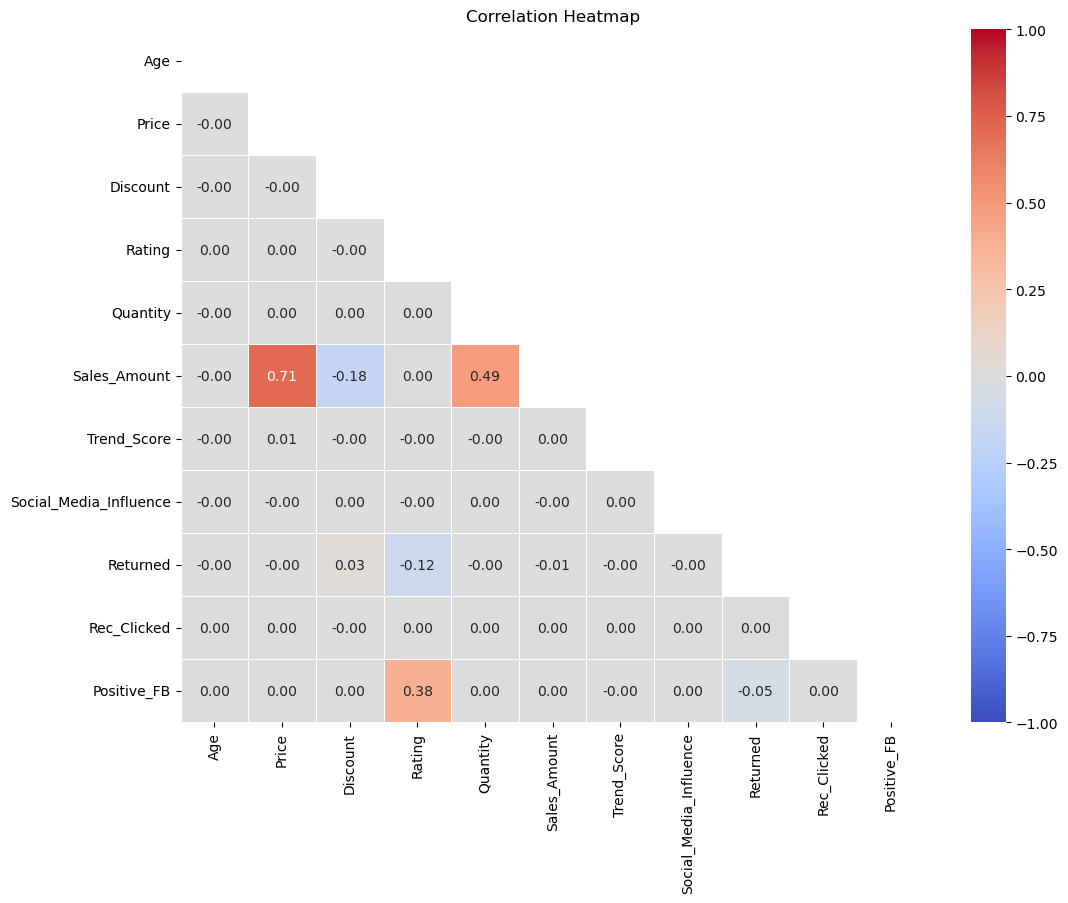

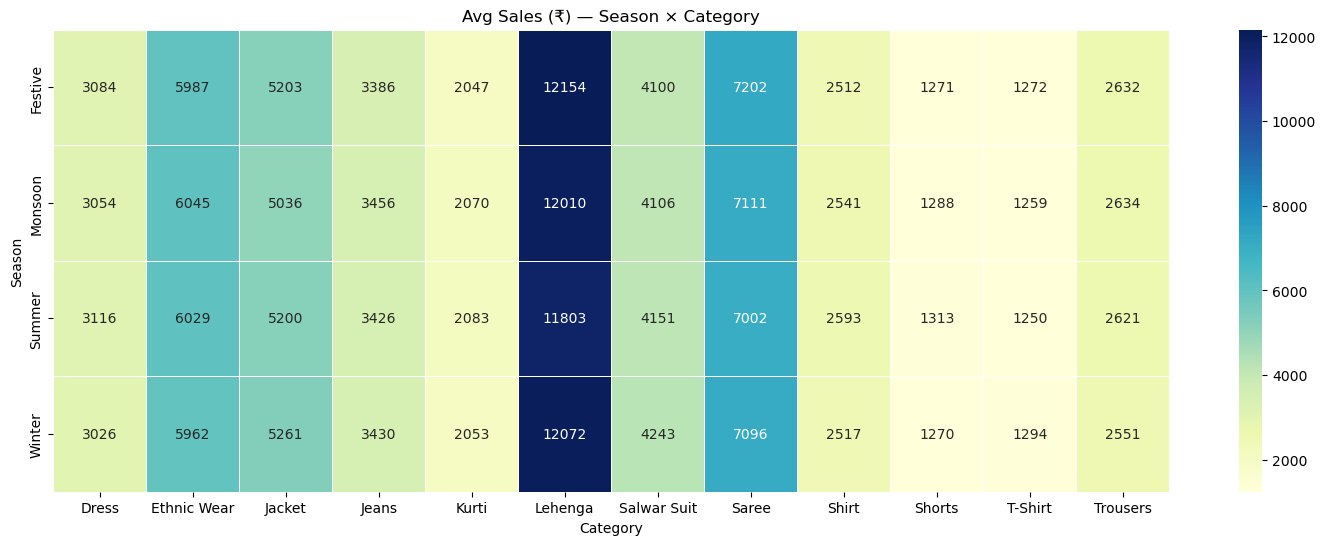

In [20]:
# --- Correlation heatmap ---
num_df = df[["Age","Price","Discount","Rating","Quantity","Sales_Amount",
             "Trend_Score","Social_Media_Influence",
             "Returned","Rec_Clicked","Positive_FB"]]
corr = num_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

# --- Season × Category heatmap (avg sales) ---
pivot = df.pivot_table(index="Season", columns="Category",
                       values="Sales_Amount", aggfunc="mean")
plt.figure(figsize=(18, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.4)
plt.title("Avg Sales (₹) — Season × Category")
plt.show()

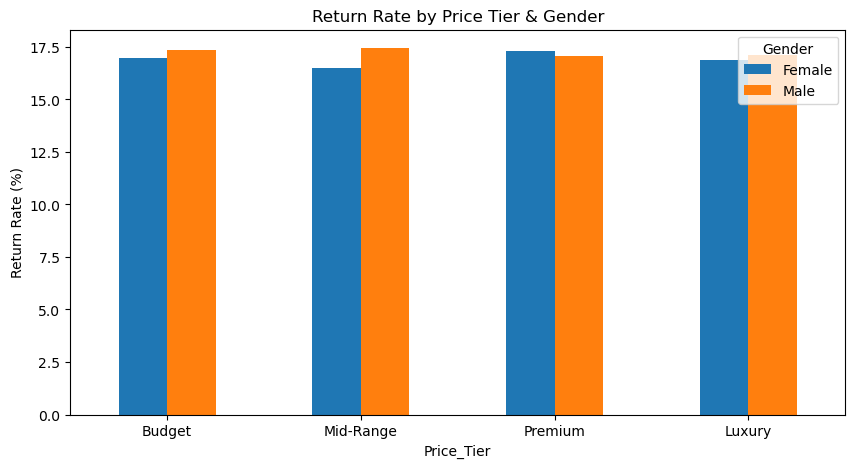

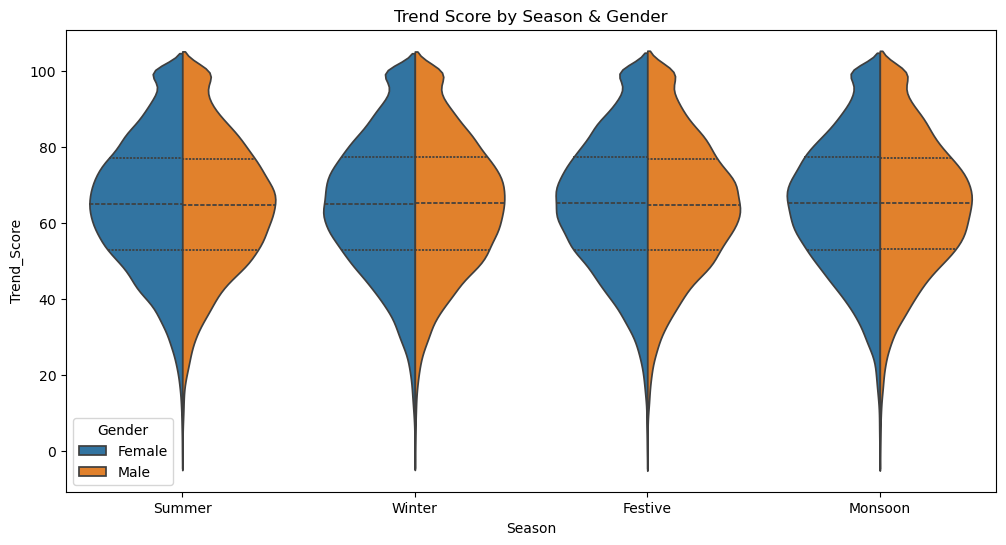

In [21]:
# --- Return rate by Price Tier & Gender ---
ret_pt = (df.groupby(["Price_Tier","Gender"], observed=True)["Returned"]
            .mean() * 100).unstack()
ret_pt.plot(kind="bar", figsize=(10, 5))
plt.title("Return Rate by Price Tier & Gender")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=0)
plt.show()

# --- Trend Score by Season & Gender (violin) ---
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x="Season", y="Trend_Score",
               hue="Gender", split=True, inner="quartile")
plt.title("Trend Score by Season & Gender")
plt.show()

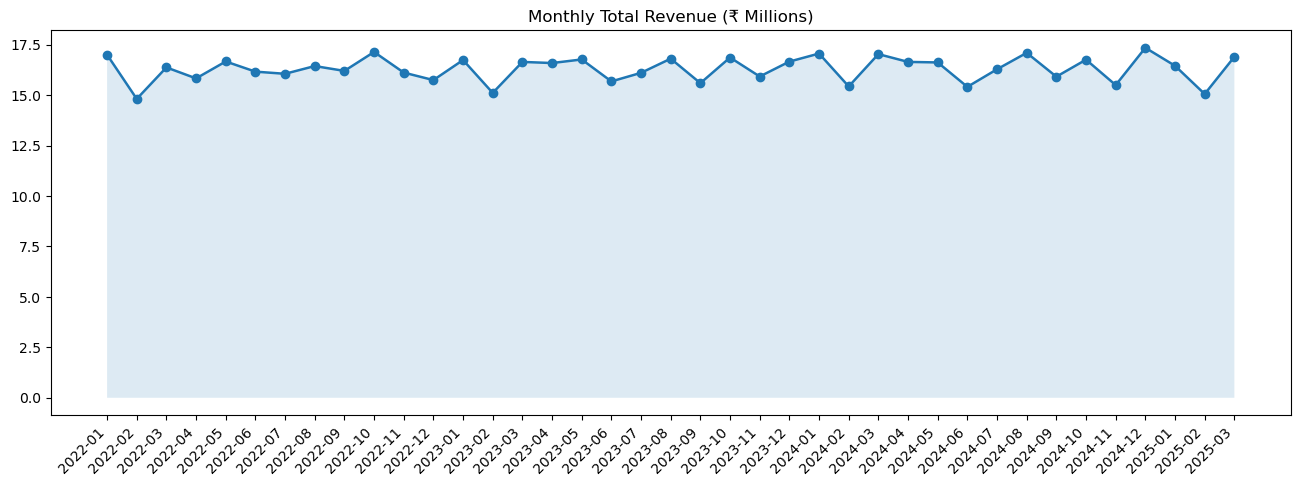

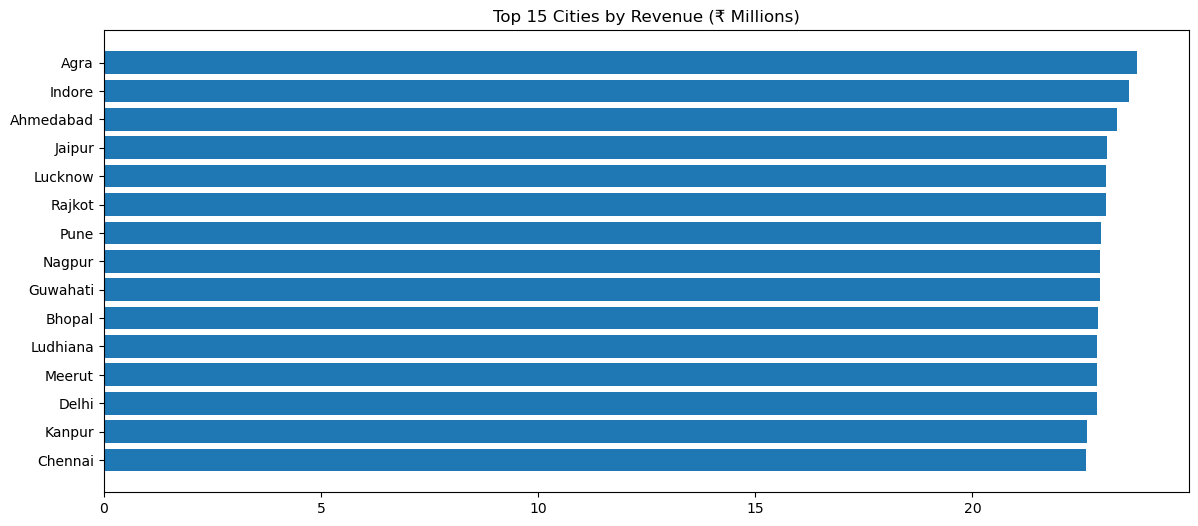

In [22]:
# --- Monthly total revenue over time ---
monthly_rev = (df.groupby(df["Purchase_Date"].dt.to_period("M"))["Sales_Amount"]
                 .sum() / 1e6)
monthly_rev.index = monthly_rev.index.astype(str)
plt.figure(figsize=(16, 5))
plt.plot(monthly_rev.index, monthly_rev.values, marker="o", linewidth=1.8)
plt.fill_between(monthly_rev.index, monthly_rev.values, alpha=0.15)
plt.xticks(rotation=45, ha="right")
plt.title("Monthly Total Revenue (₹ Millions)")
plt.show()

# --- Top 15 cities by total revenue ---
city_rev = (df.groupby("Location")["Sales_Amount"].sum() / 1e6).sort_values(ascending=False).head(15)
plt.figure(figsize=(14, 6))
plt.barh(city_rev.index[::-1], city_rev.values[::-1])
plt.title("Top 15 Cities by Revenue (₹ Millions)")
plt.show()

## STEP 5 — Computed Insight Queries

In [23]:
# Return rate overall
df["Returned"].mean() * 100

# Category with highest avg sales
df.groupby("Category")["Sales_Amount"].mean().idxmax()

# Category with highest return rate
df.groupby("Category")["Returned"].mean().idxmax()

# Peak season by total revenue
df.groupby("Season")["Sales_Amount"].sum().idxmax()

# Correlation: Social Media vs Trend Score
df["Social_Media_Influence"].corr(df["Trend_Score"])

# Recommendation CTR %
df["Rec_Clicked"].mean() * 100



np.float64(23.970666666666666)

In [24]:
# Positive feedback %
df["Positive_FB"].mean() * 100

# Top revenue city
df.groupby("Location")["Sales_Amount"].sum().idxmax()

# Weekend vs weekday avg spend
df[df["IsWeekend"]]["Sales_Amount"].mean()
df[~df["IsWeekend"]]["Sales_Amount"].mean()

# Return rate: no discount vs heavy discount
df[df["Discount"] == 0]["Returned"].mean() * 100
df[df["Discount"] > 30]["Returned"].mean() * 100

np.float64(19.931167505011157)

In [25]:
# Check required columns
required_columns = [
    "Purchase_Date",
    "Price",
    "Quantity",
    "Discount",
    "Sales_Amount",
    "Return_Status",
    "Category",
    "Brand"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Check invalid numerical values
print("Negative prices:", (df["Price"] < 0).sum())
print("Non-positive quantities:", (df["Quantity"] <= 0).sum())
print("Invalid discounts:", (
    (df["Discount"] < 0) |
    (df["Discount"] > 100)
).sum())

# Check sales calculation
calculated_sales = (
    df["Price"] *
    df["Quantity"] *
    (1 - df["Discount"] / 100)
)

difference = (
    calculated_sales - df["Sales_Amount"]
).abs()

print(
    "Rows with sales mismatches:",
    (difference > 1).sum()
)

Negative prices: 0
Non-positive quantities: 0
Invalid discounts: 0
Rows with sales mismatches: 0


## Feature 1: Create a Business KPI Summary

In [41]:
total_revenue = df["Sales_Amount"].sum()

total_transactions = len(df)

average_order_value = df["Sales_Amount"].mean()

return_rate = df["Returned"].mean() * 100

average_rating = df["Rating"].mean()

recommendation_ctr = df["Rec_Clicked"].mean() * 100

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Transactions",
        "Average Transaction Value",
        "Return Rate (%)",
        "Average Rating",
        "Recommendation Click Rate (%)"
    ],
    "Value": [
        total_revenue,
        total_transactions,
        average_order_value,
        return_rate,
        average_rating,
        recommendation_ctr
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,6.354582e+08
1,Total Transactions,1.500000e+05
2,Average Transaction Value,4.236388e+03
3,Return Rate (%),1.704200e+01
4,Average Rating,2.808196e+00
5,Recommendation Click Rate (%),2.397067e+01


In [ ]:
## Feature 2: Analyze Monthly Revenue Growth

In [42]:
monthly_revenue = (
    df.groupby(
        df["Purchase_Date"].dt.to_period("M")
    )["Sales_Amount"]
    .sum()
    .sort_index()
)

monthly_growth = monthly_revenue.pct_change() * 100

monthly_analysis = pd.DataFrame({
    "Monthly_Revenue": monthly_revenue,
    "Growth_Percentage": monthly_growth
})

monthly_analysis

,Monthly_Revenue,Growth_Percentage
Purchase_Date,,
2022-01,16998785.0,NaN
2022-02,14810291.5,-12.874411
2022-03,16370707.0,10.536022
2022-04,15827072.5,-3.320776
2022-05,16664988.5,5.294194
2022-06,16161676.0,-3.020179
2022-07,16055286.5,-0.658283
2022-08,16438797.5,2.388690
2022-09,16198204.0,-1.463571


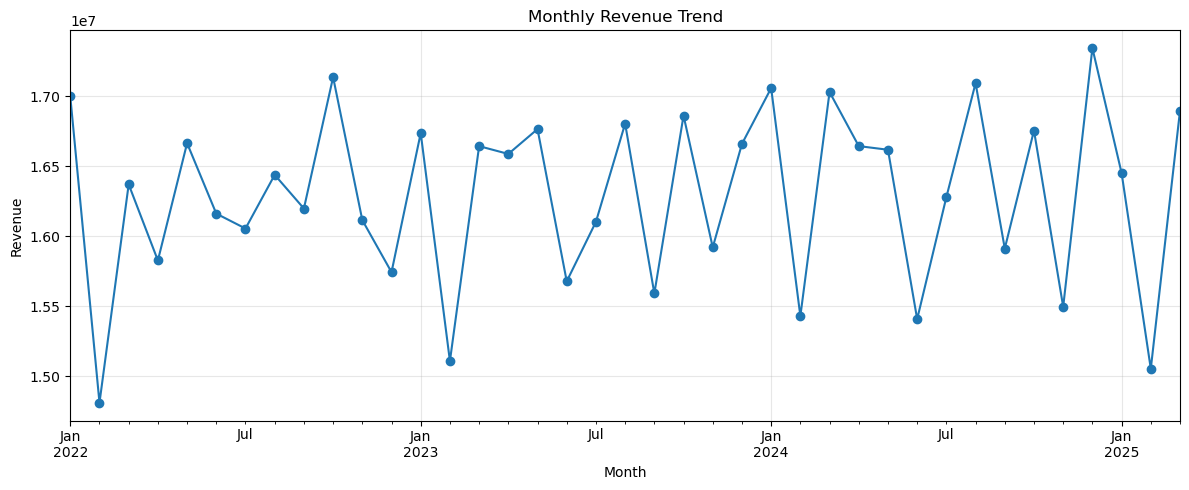

In [43]:
import matplotlib.pyplot as plt

monthly_revenue.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
## Feature 3: Customer Segmentation

In [44]:
import pandas as pd

df["Purchase_Date"] = pd.to_datetime(
    df["Purchase_Date"],
    errors="coerce"
)

reference_date = (
    df["Purchase_Date"].max()
    + pd.Timedelta(days=1)
)

customer_rfm = df.groupby("Customer_ID").agg(
    Last_Purchase=("Purchase_Date", "max"),
    Frequency=("Purchase_Date", "count"),
    Monetary=("Sales_Amount", "sum")
)

customer_rfm["Recency"] = (
    reference_date - customer_rfm["Last_Purchase"]
).dt.days

customer_rfm = customer_rfm[
    ["Recency", "Frequency", "Monetary"]
]

customer_rfm.head()

,Recency,Frequency,Monetary
Customer_ID,,,
C_10000,995,1,300.0
C_10001,703,1,2717.0
C_10002,1124,1,3450.0
C_10003,475,1,7146.0
C_10004,829,3,14438.0


In [45]:
## Feature 4: Analyze Product and Brand Performance

In [46]:
product_performance = df.groupby(
    ["Category", "Brand"]
).agg(
    Total_Revenue=("Sales_Amount", "sum"),
    Average_Sales=("Sales_Amount", "mean"),
    Average_Rating=("Rating", "mean"),
    Return_Rate=("Returned", "mean"),
    Units_Sold=("Quantity", "sum"),
    Transactions=("Sales_Amount", "count")
).reset_index()

product_performance["Return_Rate"] *= 100

product_performance = product_performance.sort_values(
    "Total_Revenue",
    ascending=False
)

product_performance.head(10)

,Category,Brand,Total_Revenue,Average_Sales,Average_Rating,Return_Rate,Units_Sold,Transactions
207,Lehenga,W,5051086.0,12691.170854,2.828894,16.582915,719,398
181,Lehenga,Biba,4917370.5,12641.055270,2.815681,21.850900,715,389
194,Lehenga,Nalli,4784932.0,12332.298969,2.792010,19.329897,694,388
179,Lehenga,Arrow,4614921.0,13185.488571,2.830857,16.571429,686,350
206,Lehenga,Varanga,4557610.5,12317.866216,2.785946,17.567568,658,370
193,Lehenga,Meena Bazaar,4554974.0,12344.102981,2.775610,17.886179,657,369
189,Lehenga,Levi'S,4535034.0,11366.000000,2.889724,18.045113,682,399
175,Lehenga,Allen Solly,4515358.0,12439.002755,2.794215,17.355372,665,363
198,Lehenga,Rangriti,4471268.0,12117.257453,2.772900,17.073171,652,369
203,Lehenga,Tisser,4446455.0,12317.049861,2.805817,15.512465,620,361


In [47]:
## Feature 5: Investigate Discounts and Returns

In [48]:
discount_analysis = df.groupby(
    "Discount_Band",
    observed=True
).agg(
    Transactions=("Sales_Amount", "count"),
    Total_Revenue=("Sales_Amount", "sum"),
    Average_Sales=("Sales_Amount", "mean"),
    Return_Rate=("Returned", "mean"),
    Average_Rating=("Rating", "mean")
)

discount_analysis["Return_Rate"] *= 100

discount_analysis

,Transactions,Total_Revenue,Average_Sales,Return_Rate,Average_Rating
Discount_Band,,,,,
No Discount,26631,141313710.0,5306.361383,16.105291,2.815106
1-10%,43870,210878264.5,4806.890005,16.526100,2.807009
11-20%,26661,114252555.0,4285.381456,16.387232,2.811080
21-30%,26397,99608060.0,3773.461378,16.611736,2.798087
31%+,26441,69405566.0,2624.922129,19.931168,2.810389


## STEP 6 — Business Questions

In [26]:
# Q1 — Revenue by category
df.groupby("Category")["Sales_Amount"].agg(["sum","mean","count"])

,sum,mean,count
Category,,,
Dress,38468418.5,3069.370342,12533
Ethnic Wear,74982727.5,6004.863258,12487
Jacket,65071762.0,5180.047922,12562
Jeans,42304750.5,3425.208526,12351
Kurti,25600362.0,2063.380511,12407
Lehenga,151121483.5,12006.155835,12587
Salwar Suit,52178902.0,4154.040443,12561
Saree,89250320.5,7099.134625,12572
Shirt,31888233.5,2542.110451,12544


In [27]:
# Q2 — Top cities by revenue
(df.groupby("Location")["Sales_Amount"].sum() / 1e6).sort_values(ascending=False).head(10)


Location
Agra         23.792558
Indore       23.604579
Ahmedabad    23.317933
Jaipur       23.093699
Lucknow      23.078198
Rajkot       23.075309
Pune         22.955080
Nagpur       22.944831
Guwahati     22.943181
Bhopal       22.896722
Name: Sales_Amount, dtype: float64

In [28]:
# Q3 — Discount vs Sales & Return Rate
df.groupby("Discount_Band", observed=True).agg(
    Avg_Sales=("Sales_Amount","mean"),
    Return_Rate=("Returned","mean"),
    Count=("Returned","count")
)

,Avg_Sales,Return_Rate,Count
Discount_Band,,,
No Discount,5306.361383,0.161053,26631
1-10%,4806.890005,0.165261,43870
11-20%,4285.381456,0.163872,26661
21-30%,3773.461378,0.166117,26397
31%+,2624.922129,0.199312,26441


In [29]:
# Q4 — Return rate by Gender × Price Tier
df.groupby(["Gender","Price_Tier"], observed=True)["Returned"].mean() * 100


Gender  Price_Tier
Female  Budget        16.986748
        Mid-Range     16.467876
        Premium       17.296157
        Luxury        16.882538
Male    Budget        17.327184
        Mid-Range     17.445959
        Premium       17.046648
        Luxury        17.125046
Name: Returned, dtype: float64

In [30]:
# Q5 — Avg spend by age group
df.groupby("Age_Group", observed=True).agg(
    Avg_Sales=("Sales_Amount","mean"),
    Avg_Price=("Price","mean"),
    Total_Customers=("Customer_ID","nunique")
)

,Avg_Sales,Avg_Price,Total_Customers
Age_Group,,,
16-24,4237.936906,2968.572337,23127
25-34,4228.583492,2985.511355,36527
35-44,4264.859981,2986.379851,25642
45-54,4234.296120,2995.223642,19519
55+,4216.671280,2976.402198,21484


In [31]:
# Q6 — Recommendation CTR by season
df.groupby("Season")["Rec_Clicked"].mean() * 100

Season
Festive    23.773772
Monsoon    24.003792
Summer     24.303114
Winter     23.791830
Name: Rec_Clicked, dtype: float64

In [32]:
# Q7 — Repeat vs single-purchase customers
cust_orders = df.groupby("Customer_ID")["Sales_Amount"].agg(["count","sum"])
single = cust_orders[cust_orders["count"] == 1]
repeat = cust_orders[cust_orders["count"] > 1]
print(len(single), len(repeat))
print(single["sum"].sum() / 1e6, repeat["sum"].sum() / 1e6)

28577 44665
120.3563975 515.101758


In [33]:
# Q8 — Top brands by avg rating
df.groupby("Brand")["Rating"].mean().sort_values(ascending=False).head(10)


Brand
Raymond         2.830491
Van Heusen      2.824055
Bunaai          2.823022
Libas           2.821353
W               2.821345
Anita Dongre    2.820570
Westside        2.819255
Arrow           2.818693
Pantaloons      2.817317
Utsa            2.816888
Name: Rating, dtype: float64

In [34]:
# Q9 — Weekend vs weekday performance
df.groupby("IsWeekend").agg(
    Avg_Sales=("Sales_Amount","mean"),
    Total_Revenue=("Sales_Amount","sum"),
    Transactions=("Sales_Amount","count")
)

,Avg_Sales,Total_Revenue,Transactions
IsWeekend,,,
False,4249.647769,455252016.5,107127
True,4203.254706,180206139.0,42873


In [35]:
# Q10 — Feedback vs Rating, Return Rate, Social Media
df.groupby("Customer_Feedback").agg(
    Avg_Rating=("Rating","mean"),
    Return_Rate=("Returned","mean"),
    Avg_Social=("Social_Media_Influence","mean")
)

,Avg_Rating,Return_Rate,Avg_Social
Customer_Feedback,,,
Negative,2.485617,0.190384,59.794131
Positive,3.103064,0.152171,59.829501


## STEP 7 — Domain-Specific Fashion Questions

In [36]:
# FQ1 — Top categories per season
pivot_season = df.groupby(["Season","Category"])["Sales_Amount"].sum().unstack()
for season in pivot_season.index:
    print(season, pivot_season.loc[season].nlargest(3))

Festive Category
Lehenga        35877972.5
Saree          20481278.5
Ethnic Wear    17105302.0
Name: Festive, dtype: float64
Monsoon Category
Lehenga        33388750.5
Saree          20721302.0
Ethnic Wear    17652131.5
Name: Monsoon, dtype: float64
Summer Category
Lehenga        39422861.5
Saree          22545578.5
Ethnic Wear    19678706.5
Name: Summer, dtype: float64
Winter Category
Lehenga        42431899.0
Saree          25502161.5
Ethnic Wear    20546587.5
Name: Winter, dtype: float64


In [37]:
# FQ2 — High trend vs low trend products
df.groupby("High_Trend")[["Sales_Amount","Social_Media_Influence","Rating"]].mean()


,Sales_Amount,Social_Media_Influence,Rating
High_Trend,,,
0,4231.370907,59.818958,2.809899
1,4251.316820,59.793721,2.803128


In [38]:
# FQ3 — Colour popularity and return rates
df.groupby("Color").agg(
    Count=("Color","count"),
    Return_Rate=("Returned","mean"),
    Avg_Sales=("Sales_Amount","mean")
).sort_values("Count", ascending=False).head(10)


,Count,Return_Rate,Avg_Sales
Color,,,
Mint,5496,0.175036,4172.594068
Gold,5436,0.170346,4256.988779
Mustard,5428,0.170781,4211.315494
Ivory,5422,0.167466,4226.217355
Green,5420,0.167528,4180.842989
Coral,5419,0.177708,4209.896383
Teal,5405,0.161887,4258.059389
Blush,5403,0.172682,4258.217657
Beige,5395,0.179611,4318.842910


In [39]:
# FQ3 — Size breakdown
df.groupby("Size", observed=True).agg(
    Count=("Size","count"),
    Return_Rate=("Returned","mean"),
    Avg_Sales=("Sales_Amount","mean")
)

,Count,Return_Rate,Avg_Sales
Size,,,
S,24940,0.173897,4238.489996
M,24960,0.170994,4252.033273
L,25058,0.169607,4202.030050


In [40]:
# FQ4 — Indian vs International brand comparison
INTERNATIONAL = {"Zara","H&M","Levi's","Arrow","Park Avenue"}
df["Brand_Origin"] = df["Brand"].apply(
    lambda b: "International" if b in INTERNATIONAL else "Indian"
)
df.groupby("Brand_Origin").agg(
    Avg_Price=("Price","mean"),
    Avg_Rating=("Rating","mean"),
    Avg_Sales=("Sales_Amount","mean"),
    Return_Rate=("Returned","mean"),
    Transactions=("Sales_Amount","count")
)

,Avg_Price,Avg_Rating,Avg_Sales,Return_Rate,Transactions
Brand_Origin,,,,,
Indian,2983.729873,2.808412,4237.082635,0.170573,132723
International,2973.870464,2.806540,4231.049198,0.169242,17277
